# Triển khai Mô hình & Suy luận Hội thoại NPC Thời gian Thực (Model Deployment & Inference)
**Dự án:** Hệ thống Nhận diện Ý định Hội thoại NPC trong Game Nhập vai (Vietnamese RPG Intent Classification)  
**Ứng dụng thực tế:** Chuyển đổi tức thì câu chat tự do của người chơi thành **Ý định (`Intent`)** + **Độ tin cậy (`Confidence`)** + **Kích hoạt sự kiện trong Game (`In-Game Action Trigger`)**

---

### Mục tiêu của Notebook
1. **Chạy độc lập ở mọi nơi (Standalone-Ready Inference)**: Nếu người dùng chỉ tải riêng lẻ file `.ipynb` này về máy hoặc mở trên Google Colab, hệ thống tự động tải trọn bộ `tfidf_vectorizer.pkl` và 5 trọng số mô hình đã huấn luyện (`.pkl`, `.pth`) từ GitHub; thậm chí nếu mất mạng hoàn toàn, hệ thống tự huấn luyện nhanh bộ mô hình dự phòng trong vài giây để đảm bảo suy luận không bao giờ lỗi.
2. **Đóng gói Bộ Suy luận Hợp nhất (`NPCDialogueEngine`)**: Nạp sẵn cả 5 mô hình lên RAM, chuẩn hóa xác suất đầu ra (`Softmax` / `Calibrated Margin`), hỗ trợ bỏ phiếu đa mô hình (*Ensemble Majority Voting*) và đo độ trễ mili-giây.
3. **Kiểm thử Sức chịu đựng (*Gamer Input Stress Test*)**: Đánh giá phản ứng của mô hình trước tiếng Việt chuẩn, gõ tắt không dấu, *teencode*, *Hard Negatives* và câu hỏi ngoài đời thực (*Out-of-Domain*).
4. **Suy luận theo Lô (*Batch Inference*) & Giả lập Logic NPC trong Game**: Ánh xạ ý định dự đoán cùng ngưỡng tin cậy (*Confidence Thresholding*) sang hành động thực tế của NPC và hướng dẫn tích hợp với `FastAPI` (`restapi/app.py`) / `Streamlit` (`app.py`).

## 0. Khởi tạo & Tự động Nạp / Tải Trọng số Mô hình (3 Tầng)
Thứ tự cấp phát tài nguyên tự động:
1. **Tầng 1**: Nạp trực tiếp từ `data/processed/` và `network/models/` nếu đang mở trong thư mục dự án.
2. **Tầng 2**: Tự động tải `tfidf_vectorizer.pkl`, `nb_model.pkl`, `svm_model.pkl`, `lr_model.pkl`, `ReLU.pth`, `SiLU.pth` từ kho GitHub về `./standalone_workspace/` nếu chạy file lẻ có mạng.
3. **Tầng 3**: Tự động sinh dữ liệu RPG tiếng Việt và huấn luyện nhanh cả 5 mô hình ngay trong bộ nhớ nếu chạy lẻ hoàn toàn ngoại tuyến.

In [1]:
import importlib.util
import json
import os
import pickle
import subprocess
import sys
import time
import urllib.request
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

REQUIRED_PACKAGES = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn", "torch": "torch", "matplotlib": "matplotlib"}
missing_pkgs = [pip_name for mod, pip_name in REQUIRED_PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing_pkgs:
    print(f"[Setup] Đang cài đặt gói thư viện thiếu: {missing_pkgs} ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_pkgs])

try:
    import packaging.version
    sys.modules.setdefault("torch._vendor.packaging.version", packaging.version)
except Exception:
    pass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Segoe UI", "Arial"]
plt.rcParams["axes.unicode_minus"] = False

INTENT_NAMES = ["GREETING", "TRADE", "INFO", "HOSTILE", "UNKNOWN"]
INTENT_TO_ID = {name: i for i, name in enumerate(INTENT_NAMES)}
ID_TO_INTENT = {i: name for i, name in enumerate(INTENT_NAMES)}
INTENT_COLORS = {"GREETING": "#2ca02c", "TRADE": "#1f77b4", "INFO": "#ff7f0e", "HOSTILE": "#d62728", "UNKNOWN": "#9467bd"}
GITHUB_RAW_BASE = "https://raw.githubusercontent.com/DianLiberos/intent-classification/main"

class NeuralNetwork(nn.Module):
    """Kiến trúc PyTorch MLP chuẩn của dự án: 2000 -> 512 -> Act -> Dropout(0.5) -> 128 -> Act -> Dropout(0.5) -> 5"""
    def __init__(self, activation_function: str = "ReLU", dropout_p: float = 0.5):
        super().__init__()
        if activation_function == "ReLU":
            act = nn.ReLU
        elif activation_function == "SiLU":
            act = nn.SiLU
        else:
            raise ValueError(f"Unsupported activation_function: {activation_function}")

        self.sequential_stack = nn.Sequential(
            nn.Linear(2000, 512),
            act(),
            nn.Dropout(dropout_p),
            nn.Linear(512, 128),
            act(),
            nn.Dropout(dropout_p),
            nn.Linear(128, 5),
        )

    def forward(self, x):
        return self.sequential_stack(x)


def _synthesize_offline_rpg_dataset(data_dir: Path, n_train_seeds: int = 80, n_test_seeds: int = 30):
    """Tier 3 Fallback: Sinh bộ dữ liệu RPG tiếng Việt chuẩn Zero-Leakage khi chạy lẻ hoàn toàn Offline."""
    import random, re, unicodedata, csv
    rng = random.Random(42)
    data_dir.mkdir(parents=True, exist_ok=True)

    vocab = {
        "pronoun": ["tôi", "tui", "mình", "em", "anh", "tại hạ", "kẻ lữ hành này", "tao"],
        "npc": ["ông chủ", "chủ tiệm", "shop", "lão bản", "thợ rèn", "thương nhân", "trưởng làng", "tiền bối"],
        "greet": ["xin chào", "chào", "hello", "hi", "alo", "kính chào", "bái kiến", "hú"],
        "item": ["kiếm sắt", "đại đao", "cung gỗ", "giáp sắt", "bình máu", "bình mana", "đá cường hóa", "quặng sắt", "vảy rồng"],
        "currency": ["vàng", "bạc", "xu", "kim cương", "gold", "linh thạch"],
        "buy": ["mua", "lấy", "tậu", "chốt", "sắm", "đổi lấy"],
        "loc": ["rừng phía bắc", "hang nhện", "đầm lầy tử thần", "làng tân thủ", "tháp ma thuật", "hầm ngục tối"],
        "monster": ["goblin", "slime", "rồng lửa", "quỷ vương", "sói xám", "nhện độc"],
        "quest": ["nhiệm vụ", "quest", "ủy thác", "bản đồ kho báu", "mật thư"],
        "insult": ["đồ phế vật", "thằng lừa đảo", "đồ ăn hại", "lão già dịch", "đồ hút máu"],
        "hostile": ["đập nát tiệm", "đốt quán", "chém chết", "cướp sạch", "san phẳng chỗ này"],
        "ood": ["bitcoin", "trà sữa trân châu", "code Python", "iPhone 16", "giá xăng hôm nay", "Ngoại hạng Anh", "mật khẩu wifi"],
    }

    train_tpl = {
        "GREETING": [
            "{greet} {npc}, chúc một ngày tốt lành!",
            "{npc} ơi, {pronoun} mới tới vùng này, {greet} nhé!",
            "Lâu quá không gặp {npc}, dạo này vẫn khỏe chứ?",
            "{greet} {npc}, {pronoun} vừa đi săn ở {loc} về ghé chào một tiếng!",
        ],
        "TRADE": [
            "{npc} ơi, bán cho {pronoun} một cái {item} tính bằng {currency} với.",
            "Món {item} này giá bao nhiêu {currency} vậy {npc}?",
            "{pronoun} muốn {buy} ít {item}, mở kho hàng xem thử nào!",
            "Giảm giá món {item} chút đi {npc}, {pronoun} {buy} liền trả đủ {currency}!",
        ],
        "INFO": [
            "{npc} cho {pronoun} hỏi đường đi tới {loc} ở hướng nào vậy?",
            "Làm sao để hạ gục con {monster} ở {loc} thế {npc}?",
            "Ở đây có {quest} nào mới cho {pronoun} nhận không {npc}?",
            "Đánh con {monster} ở {loc} thì rớt nguyên liệu {item} nào vậy?",
        ],
        "HOSTILE": [
            "Đồ {insult}, hôm nay {pronoun} sẽ {hostile} của mày!",
            "Bán {item} giá cắt cổ thế à, định cướp cạn hả {insult}?",
            "Cút ngay trước khi tao nổi điên tới {hostile} đồ {insult}!",
            "Nhìn mặt {npc} ngứa mắt thật sự, bước ra đây solo đi {insult}!",
        ],
        "UNKNOWN": [
            "{npc} ơi, hôm nay giá {ood} ngoài đời là bao nhiêu tiền vậy?",
            "Chỉ giúp {pronoun} cách học {ood} sao cho nhanh giỏi với!",
            "Quanh đây có quán nào bán {ood} giao tận nhà không nhỉ?",
            "Đổi 1000 {currency} trong game lấy {ood} ngoài đời thật được không shop?",
        ],
    }

    test_tpl = {
        "GREETING": [
            "Ồ {npc} vẫn canh tiệm đấy à, {greet} buổi sáng nha!",
            "Một ngày bình an nhé {npc}, {pronoun} ghé qua điểm danh cái!",
        ],
        "TRADE": [
            "Thanh toán cho {pronoun} món {item} bằng {currency} lẹ đi {npc}!",
            "Có nhận trao đổi {item} cũ bù thêm {currency} lấy đồ mới không shop?",
        ],
        "INFO": [
            "Bí kíp nào vượt ải {loc} mà không bị {monster} đánh bại vậy {npc}?",
            "Ai là người giao {quest} thám hiểm vùng {loc} hả {npc}?",
        ],
        "HOSTILE": [
            "Tiệm rách nát bán toàn {item} dỏm, dẹp tiệm đi đồ {insult}!",
            "Nói thêm câu nữa là tao {hostile} ngay tại chỗ đấy {insult}!",
        ],
        "UNKNOWN": [
            "Tư vấn giùm {pronoun} có nên đầu tư vào {ood} năm nay không?",
            "Ngoài đời đang bận {ood} mà tự nhiên vô game hỏi {npc} làm chi không biết!",
        ],
    }

    def strip_accents(s: str) -> str:
        s = re.sub(r"[đ]", "d", re.sub(r"[Đ]", "D", s))
        return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")

    def to_teencode(s: str) -> str:
        out = s.lower()
        subs = [(r"\bkhông\b", "ko"), (r"\bbao nhiêu\b", "bn"), (r"\bông chủ\b", "shop"),
                (r"\btôi\b", "tui"), (r"\bvậy\b", "z"), (r"\bvới\b", "vs"), (r"\bđược\b", "dc")]
        for pat, rep in subs:
            if rng.random() < 0.75:
                out = re.sub(pat, rep, out)
        return re.sub(r"[!?.]+$", "", out).strip()

    def fill(tpl: str) -> str:
        out = tpl
        for k in re.findall(r"\{(\w+)\}", tpl):
            out = out.replace(f"{{{k}}}", rng.choice(vocab[k]), 1)
        return out

    def make_split(tpl_map, seeds_per_intent, seen_norm):
        rows = []
        for intent, tpls in tpl_map.items():
            cnt, tries = 0, 0
            while cnt < seeds_per_intent and tries < seeds_per_intent * 40:
                tries += 1
                seed = fill(rng.choice(tpls))
                key = strip_accents(seed.lower())
                if key in seen_norm:
                    continue
                seen_norm.add(key)
                cnt += 1
                v1 = seed
                v2 = to_teencode(seed)
                v3 = strip_accents(v2)
                v4 = f"ê {v2} nha"
                for v in (v1, v2, v3, v4):
                    rows.append({"text": v, "intent": intent})
        rng.shuffle(rows)
        return rows

    seen = set()
    train_rows = make_split(train_tpl, n_train_seeds, seen)
    test_rows = make_split(test_tpl, n_test_seeds, seen)
    full_rows = train_rows + test_rows

    (data_dir / "train.json").write_text(json.dumps(train_rows, ensure_ascii=False, indent=2), encoding="utf-8")
    (data_dir / "test.json").write_text(json.dumps(test_rows, ensure_ascii=False, indent=2), encoding="utf-8")
    (data_dir / "dataset_full.json").write_text(json.dumps(full_rows, ensure_ascii=False, indent=2), encoding="utf-8")

    intents_list = list(train_tpl.keys())
    with open(data_dir / "dataset_ver1.csv", "w", encoding="utf-8", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["id", "text", "annonator_1", "annonator_2", "final intent"])
        for idx, row in enumerate(train_rows[:200], start=1):
            a1 = row["intent"]
            a2 = a1 if rng.random() > 0.08 else rng.choice(intents_list)
            writer.writerow([idx, row["text"], a1, a2, row["intent"]])

    return train_rows, test_rows


def bootstrap_inference_artifacts() -> tuple[Path, Path, str]:
    force_standalone = os.environ.get("FORCE_STANDALONE_TEST", "0") == "1"
    force_offline = os.environ.get("FORCE_OFFLINE_FALLBACK", "0") == "1"

    if not force_standalone:
        cwd = Path.cwd().resolve()
        for root in [cwd, cwd.parent, cwd.parent.parent, cwd / "intent-classification"]:
            proc = root / "data" / "processed"
            nn_dir = root / "network" / "models"
            if (proc / "tfidf_vectorizer.pkl").exists() and (proc / "nb_model.pkl").exists():
                return proc, nn_dir, f"Tầng 1 - Trọng số huấn luyện sẵn từ dự án ({root})"

    ws = Path.cwd().resolve() / "standalone_workspace"
    ws_data, ws_proc, ws_nn = ws / "data", ws / "processed", ws / "models"
    for d in (ws_data, ws_proc, ws_nn / "ReLU", ws_nn / "SiLU"):
        d.mkdir(parents=True, exist_ok=True)

    required_targets = [
        ("data/processed/tfidf_vectorizer.pkl", ws_proc / "tfidf_vectorizer.pkl"),
        ("data/processed/nb_model.pkl", ws_proc / "nb_model.pkl"),
        ("data/processed/svm_model.pkl", ws_proc / "svm_model.pkl"),
        ("data/processed/lr_model.pkl", ws_proc / "lr_model.pkl"),
        ("network/models/ReLU/ReLU.pth", ws_nn / "ReLU" / "ReLU.pth"),
        ("network/models/SiLU/SiLU.pth", ws_nn / "SiLU" / "SiLU.pth"),
    ]

    if all(dst.exists() for _, dst in required_targets) and not force_offline:
        return ws_proc, ws_nn, f"Tầng 2 - Cache trọng số độc lập ({ws})"

    if not force_offline:
        try:
            print("[Bootstrap] Đang tải bộ Vectorizer & 5 trọng số mô hình từ GitHub...")
            for rel_url, dst in required_targets:
                req = urllib.request.Request(f"{GITHUB_RAW_BASE}/{rel_url}", headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(req, timeout=15) as resp:
                    dst.write_bytes(resp.read())
                print(f"  + Đã tải: {dst.name} ({dst.stat().st_size / 1024:.1f} KB)")
            return ws_proc, ws_nn, f"Tầng 2 - Trọng số tải tự động từ GitHub ({ws})"
        except Exception as err:
            print(f"[Bootstrap] Không thể tải trọng số từ GitHub ({err}). Kích hoạt Tầng 3 (Offline Auto-Train)...")

    # Tầng 3: Sinh dữ liệu và huấn luyện tức thì cả 5 mô hình trong vài giây
    train_rows, _ = _synthesize_offline_rpg_dataset(ws_data)
    vec = TfidfVectorizer(max_features=2000, ngram_range=(1, 2), sublinear_tf=True)
    X_tr = vec.fit_transform([r["text"] for r in train_rows])
    y_tr = np.array([INTENT_TO_ID[r["intent"]] for r in train_rows])

    with open(ws_proc / "tfidf_vectorizer.pkl", "wb") as f:
        pickle.dump(vec, f)

    for fn, clf in [
        ("nb_model.pkl", MultinomialNB(alpha=1.0)),
        ("svm_model.pkl", LinearSVC(C=0.1, dual=False, random_state=42)),
        ("lr_model.pkl", LogisticRegression(C=1.0, max_iter=1000, random_state=42)),
    ]:
        clf.fit(X_tr, y_tr)
        with open(ws_proc / fn, "wb") as f:
            pickle.dump(clf, f)

    arr = X_tr.toarray().astype(np.float32)
    if arr.shape[1] < 2000:
        arr = np.hstack([arr, np.zeros((arr.shape[0], 2000 - arr.shape[1]), dtype=np.float32)])
    ds_loader = DataLoader(TensorDataset(torch.from_numpy(arr), torch.from_numpy(y_tr).long()), batch_size=64, shuffle=True)

    for act in ("ReLU", "SiLU"):
        torch.manual_seed(42)
        nn_m = NeuralNetwork(activation_function=act)
        opt = torch.optim.Adam(nn_m.parameters(), lr=1e-3)
        loss_fn = nn.CrossEntropyLoss()
        nn_m.train()
        for _ in range(15):
            for xb, yb in ds_loader:
                opt.zero_grad()
                loss_fn(nn_m(xb), yb).backward()
                opt.step()
        torch.save(nn_m.state_dict(), ws_nn / act / f"{act}.pth")

    return ws_proc, ws_nn, f"Tầng 3 - Trọng số tự huấn luyện Offline ({ws})"


PROCESSED_DIR, MODELS_DIR, ARTIFACT_SOURCE = bootstrap_inference_artifacts()
print(f"✅ Nguồn mô hình sẵn sàng: {ARTIFACT_SOURCE}")

✅ Nguồn mô hình sẵn sàng: Tầng 1 - Trọng số huấn luyện sẵn từ dự án (D:\project may hoc\intent-classification)


## 1. Xây dựng Lớp Suy luận Hợp nhất `NPCDialogueEngine`
Lớp `NPCDialogueEngine` dưới đây đóng gói toàn bộ quy trình tiền xử lý và dự đoán giống như sự kết hợp giữa `backend/text_converter.py`, `app.py` và `restapi/app.py`, đồng thời bổ sung:
- Tính toán phân phối xác suất `probabilities` trên cả 5 nhãn (sử dụng `predict_proba` cho Naive Bayes / Logistic Regression, `Softmax` trên `decision_function` cho Linear SVM và `Softmax` trên `logits` cho PyTorch MLP).
- Chế độ **Ensemble Consensus** kết hợp cả 5 mô hình để tăng độ tin cậy cho các câu hội thoại biên.

In [2]:
class NPCDialogueEngine:
    '''Bộ máy suy luận đa mô hình cho hội thoại NPC thời gian thực.'''

    def __init__(self, processed_dir: Path, models_dir: Path):
        with open(processed_dir / "tfidf_vectorizer.pkl", "rb") as f:
            self.vectorizer = pickle.load(f)

        self.engines = {}
        sklearn_files = [
            ("Multinomial NB", "nb_model.pkl"),
            ("Linear SVM", "svm_model.pkl"),
            ("Logistic Regression", "lr_model.pkl"),
        ]
        for name, fn in sklearn_files:
            p = processed_dir / fn
            if p.exists():
                with open(p, "rb") as f:
                    self.engines[name] = {"type": "sklearn", "model": pickle.load(f)}

        for act in ("ReLU", "SiLU"):
            pth = models_dir / act / f"{act}.pth"
            if pth.exists():
                net = NeuralNetwork(activation_function=act)
                net.load_state_dict(torch.load(pth, map_location="cpu", weights_only=True))
                net.eval()
                self.engines[f"PyTorch MLP ({act})"] = {"type": "pytorch", "model": net}

    @staticmethod
    def _softmax(scores: np.ndarray) -> np.ndarray:
        shifted = scores - np.max(scores)
        exp_s = np.exp(shifted)
        return exp_s / np.sum(exp_s)

    def _pad_dense_2000(self, sparse_vec) -> np.ndarray:
        arr = sparse_vec.toarray().astype(np.float32)
        if arr.shape[1] < 2000:
            arr = np.hstack([arr, np.zeros((arr.shape[0], 2000 - arr.shape[1]), dtype=np.float32)])
        return arr

    def predict(self, text: str, engine_name: str = "Multinomial NB") -> dict:
        if engine_name not in self.engines:
            raise KeyError(f"Engine '{engine_name}' không tồn tại. Có sẵn: {list(self.engines.keys())}")

        info = self.engines[engine_name]
        mdl = info["model"]

        t0 = time.perf_counter()
        sparse_vec = self.vectorizer.transform([text])
        active_tokens = int(sparse_vec.nnz)

        if info["type"] == "sklearn":
            if hasattr(mdl, "predict_proba"):
                probs = mdl.predict_proba(sparse_vec)[0]
            else:
                margins = mdl.decision_function(sparse_vec)[0]
                probs = self._softmax(margins)
            pred_id = int(np.argmax(probs))
        else:
            dense_arr = self._pad_dense_2000(sparse_vec)
            with torch.no_grad():
                logits = mdl(torch.from_numpy(dense_arr))[0].numpy()
            probs = self._softmax(logits)
            pred_id = int(np.argmax(probs))

        latency_ms = (time.perf_counter() - t0) * 1000
        return {
            "text": text,
            "engine": engine_name,
            "intent": ID_TO_INTENT[pred_id],
            "confidence": round(float(probs[pred_id]) * 100, 2),
            "probabilities": {INTENT_NAMES[i]: round(float(probs[i]) * 100, 2) for i in range(5)},
            "active_features": active_tokens,
            "latency_ms": round(latency_ms, 4),
        }

    def predict_consensus(self, text: str) -> dict:
        per_engine = {eng: self.predict(text, eng) for eng in self.engines}
        avg_probs = np.mean([[res["probabilities"][it] for it in INTENT_NAMES] for res in per_engine.values()], axis=0)
        best_idx = int(np.argmax(avg_probs))
        votes = [res["intent"] for res in per_engine.values()]
        consensus_intent = ID_TO_INTENT[best_idx]
        agreement_ratio = votes.count(consensus_intent) / len(votes) * 100
        return {
            "text": text,
            "consensus_intent": consensus_intent,
            "consensus_confidence": round(float(avg_probs[best_idx]), 2),
            "agreement_pct": round(agreement_ratio, 1),
            "votes_by_engine": {eng: res["intent"] for eng, res in per_engine.items()},
        }


engine = NPCDialogueEngine(PROCESSED_DIR, MODELS_DIR)
print(f"⚡ Đã nạp thành công {len(engine.engines)} mô hình lên RAM: {list(engine.engines.keys())}")

⚡ Đã nạp thành công 5 mô hình lên RAM: ['Multinomial NB', 'Linear SVM', 'Logistic Regression', 'PyTorch MLP (ReLU)', 'PyTorch MLP (SiLU)']


## 2. Suy luận Đơn lẻ & Trực quan hóa Phân phối Độ tin cậy (*Confidence Distribution*)
Thử nghiệm dự đoán trên các câu thoại tiêu biểu mang nhiều sắc thái khác nhau (gõ không dấu, *teencode*, *hard negative* chứa từ vật phẩm nhưng mang hàm ý công kích hoặc hỏi cốt truyện) và vẽ biểu đồ xác suất trên 5 nhãn.

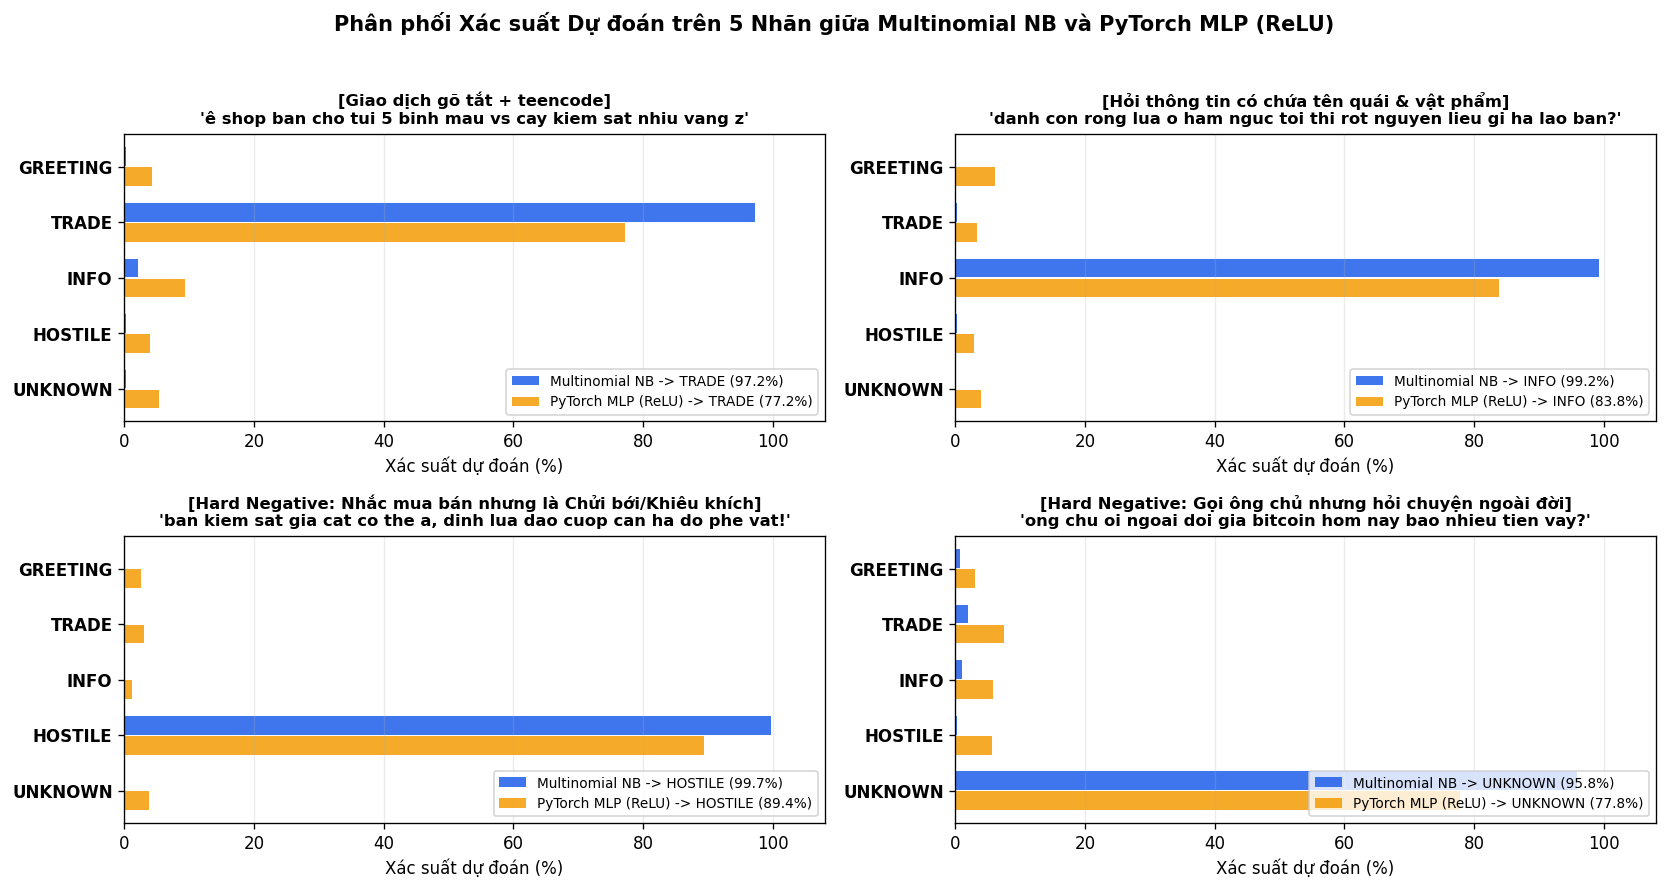

In [3]:
showcase_queries = [
    ("ê shop ban cho tui 5 binh mau vs cay kiem sat nhiu vang z", "Giao dịch gõ tắt + teencode"),
    ("danh con rong lua o ham nguc toi thi rot nguyen lieu gi ha lao ban?", "Hỏi thông tin có chứa tên quái & vật phẩm"),
    ("ban kiem sat gia cat co the a, dinh lua dao cuop can ha do phe vat!", "Hard Negative: Nhắc mua bán nhưng là Chửi bới/Khiêu khích"),
    ("ong chu oi ngoai doi gia bitcoin hom nay bao nhieu tien vay?", "Hard Negative: Gọi ông chủ nhưng hỏi chuyện ngoài đời"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 7.2))
for ax, (q_text, desc) in zip(axes.ravel(), showcase_queries):
    res_nb = engine.predict(q_text, "Multinomial NB")
    res_mlp = engine.predict(q_text, "PyTorch MLP (ReLU)")

    y_idx = np.arange(len(INTENT_NAMES))
    nb_vals = [res_nb["probabilities"][it] for it in INTENT_NAMES]
    mlp_vals = [res_mlp["probabilities"][it] for it in INTENT_NAMES]

    ax.barh(y_idx - 0.18, nb_vals, height=0.34, label=f"Multinomial NB -> {res_nb['intent']} ({res_nb['confidence']:.1f}%)", color="#2563eb", alpha=0.88)
    ax.barh(y_idx + 0.18, mlp_vals, height=0.34, label=f"PyTorch MLP (ReLU) -> {res_mlp['intent']} ({res_mlp['confidence']:.1f}%)", color="#f59e0b", alpha=0.88)
    ax.set_yticks(y_idx, INTENT_NAMES, fontweight="bold")
    ax.invert_yaxis()
    ax.set_xlim(0, 108)
    ax.set_xlabel("Xác suất dự đoán (%)")
    ax.set_title(f"[{desc}]\n'{q_text}'", fontsize=9.8, fontweight="bold")
    ax.legend(loc="lower right", fontsize=8.2)
    ax.grid(axis="x", alpha=0.25)

plt.suptitle("Phân phối Xác suất Dự đoán trên 5 Nhãn giữa Multinomial NB và PyTorch MLP (ReLU)", fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 3. Suy luận theo Lô (*Batch Inference*), Đối sánh Đồng thuận 5 Mô hình & Đo Tốc độ (*Throughput*)
Trong môi trường máy chủ game phục vụ hàng trăm người chơi cùng lúc, ta cần kiểm tra mức độ đồng thuận giữa các mô hình trên một lô truy vấn hỗn hợp và đo thông lượng xử lý thực tế (số truy vấn/giây).

In [4]:
batch_test_cases = [
    ("Xin chào trưởng làng, kẻ lữ hành này mới đặt chân tới vùng đất này!", "GREETING"),
    ("hi shop buoi sang vui ve nha", "GREETING"),
    ("gói nhanh cho tui 10 bình mana tính bằng vàng nhé chủ tiệm", "TRADE"),
    ("cuong hoa cai giap vay rong nay len cap ton bn xu z shop", "TRADE"),
    ("Từ làng tân thủ muốn đi tới tháp ma thuật thì rẽ hướng nào vậy tiền bối?", "INFO"),
    ("lam nv gi de nhan dc chung chi tho san ha ong chu", "INFO"),
    ("đồ lừa đảo bán đồ rác rưởi, bước ra đây tao đập nát tiệm bây giờ!", "HOSTILE"),
    ("nhin mat thang chu quan ngua mat vl, thich an don ko", "HOSTILE"),
    ("tối nay Ngoại hạng Anh đá mấy giờ vậy shop ơi", "UNKNOWN"),
    ("giải giùm bài tập code Python mạng nơ ron PyTorch này với đau đầu quá", "UNKNOWN"),
]

batch_rows = []
for query, expected in batch_test_cases:
    cons = engine.predict_consensus(query)
    row = {
        "Câu chat người chơi": query,
        "Kỳ vọng": expected,
        "NB": cons["votes_by_engine"].get("Multinomial NB", "-"),
        "MLP(ReLU)": cons["votes_by_engine"].get("PyTorch MLP (ReLU)", "-"),
        "MLP(SiLU)": cons["votes_by_engine"].get("PyTorch MLP (SiLU)", "-"),
        "SVM": cons["votes_by_engine"].get("Linear SVM", "-"),
        "Consensus": cons["consensus_intent"],
        "Đồng thuận (%)": cons["agreement_pct"],
    }
    batch_rows.append(row)

df_batch = pd.DataFrame(batch_rows)
print("=== KẾT QUẢ SUY LUẬN THEO LÔ & BỎ PHIẾU ĐỒNG THUẬN 5 MÔ HÌNH ===")
print(df_batch.to_string(index=False))

# Đo tốc độ thực tế qua 500 lần gọi liên tiếp cho từng Engine
N_BENCH_CALLS = 500
sample_q = "ong chu co ban kiem sat va binh mau khong?"
speed_rows = []
for eng_name in engine.engines:
    for _ in range(20):
        engine.predict(sample_q, eng_name)  # warm-up
    t0 = time.perf_counter()
    for _ in range(N_BENCH_CALLS):
        engine.predict(sample_q, eng_name)
    total_ms = (time.perf_counter() - t0) * 1000
    avg_lat = total_ms / N_BENCH_CALLS
    qps = 1000.0 / avg_lat if avg_lat > 0 else 0
    speed_rows.append({
        "Engine Suy luận": eng_name,
        "Độ trễ Đơn lẻ (ms / câu)": round(avg_lat, 4),
        "Thông lượng Ước tính (Queries / giây)": f"{int(qps):,}",
    })

print(f"\n=== ĐO TỐC ĐỘ PHẢN HỒI THỜI GIAN THỰC ({N_BENCH_CALLS} TRUY VẤN ĐƠN LẺ LIÊN TIẾP) ===")
pd.DataFrame(speed_rows)

=== KẾT QUẢ SUY LUẬN THEO LÔ & BỎ PHIẾU ĐỒNG THUẬN 5 MÔ HÌNH ===
                                                     Câu chat người chơi  Kỳ vọng       NB MLP(ReLU) MLP(SiLU)      SVM Consensus  Đồng thuận (%)
     Xin chào trưởng làng, kẻ lữ hành này mới đặt chân tới vùng đất này! GREETING GREETING  GREETING  GREETING GREETING  GREETING           100.0
                                            hi shop buoi sang vui ve nha GREETING GREETING  GREETING  GREETING GREETING  GREETING           100.0
              gói nhanh cho tui 10 bình mana tính bằng vàng nhé chủ tiệm    TRADE    TRADE     TRADE     TRADE    TRADE     TRADE           100.0
                cuong hoa cai giap vay rong nay len cap ton bn xu z shop    TRADE    TRADE     TRADE     TRADE    TRADE     TRADE           100.0
Từ làng tân thủ muốn đi tới tháp ma thuật thì rẽ hướng nào vậy tiền bối?     INFO     INFO      INFO      INFO     INFO      INFO           100.0
                       lam nv gi de nhan dc chung chi tho s

,Engine Suy luận,Độ trễ Đơn lẻ (ms / câu),Thông lượng Ước tính (Queries / giây)
0,Multinomial NB,1.9848,503
1,Linear SVM,1.7126,583
2,Logistic Regression,2.0194,495
3,PyTorch MLP (ReLU),2.9575,338
4,PyTorch MLP (SiLU),2.7815,359


## 4. Giả lập Tích hợp vào Game Engine (*In-Game NPC Action Dispatcher*)
Trong kiến trúc game thực tế, nhãn dự đoán của mô hình được kết hợp với **Ngưỡng tin cậy an toàn (`CONFIDENCE_THRESHOLD`)** và số đặc trưng khớp từ điển (`active_features`) trước khi kích hoạt sự kiện trong game:
- Nếu câu nhập hoàn toàn lạ (`active_features == 0`) hoặc độ tin cậy thấp hơn ngưỡng, hệ thống tự động chuyển về kịch bản `FALLBACK_CONFUSED` để tránh mở nhầm cửa hàng hoặc kích hoạt chiến đấu oan.

In [5]:
NPC_ACTION_TABLE = {
    "GREETING": {
        "game_event": "TRIGGER_GREETING_ANIM",
        "ui_module": "DialogueBubble",
        "npc_reply": "Chào người anh em lữ hành! Hôm nay ghé tiệm rèn của lão có việc gì cần giúp nào?",
    },
    "TRADE": {
        "game_event": "OPEN_SHOP_INVENTORY_UI",
        "ui_module": "MerchantWindow",
        "npc_reply": "Mắt nhìn tinh đấy! Kho vũ khí và dược phẩm thượng hạng của tiệm đều ở đây, cứ tự nhiên chọn nhé!",
    },
    "INFO": {
        "game_event": "OPEN_QUEST_AND_MAP_PANE",
        "ui_module": "QuestJournalUI",
        "npc_reply": "Vùng đất phía trước đầy rẫy hiểm nguy... Để lão đánh dấu vị trí và thông tin nhiệm vụ lên bản đồ cho ngươi!",
    },
    "HOSTILE": {
        "game_event": "ALERT_TOWN_GUARDS_COMBAT",
        "ui_module": "ReputationWarningHUD",
        "npc_reply": "Hỗn xược! Ngươi dám tới tiệm của ta gây sự à? Lính gác thành đâu, bắt lấy kẻ gây rối này!",
    },
    "UNKNOWN": {
        "game_event": "PLAY_SHRUG_EMOTE",
        "ui_module": "DialogueBubble",
        "npc_reply": "Hả... ngươi đang lẩm bẩm thứ ngôn ngữ kỳ lạ của thế giới nào vậy? Lão chỉ rành chuyện rèn đúc và quái vật thôi!",
    },
}

def dispatch_npc_interaction(player_message: str, model_name: str = "Multinomial NB", min_conf: float = 45.0) -> dict:
    pred = engine.predict(player_message, engine_name=model_name)
    effective_intent = pred["intent"]
    guard_note = "OK"

    if pred["active_features"] == 0:
        effective_intent = "UNKNOWN"
        guard_note = "OOV Fallback (0 từ khớp từ điển)"
    elif pred["confidence"] < min_conf:
        effective_intent = "UNKNOWN"
        guard_note = f"Low-Confidence Fallback (< {min_conf}%)"

    action = NPC_ACTION_TABLE[effective_intent]
    return {
        "player_input": player_message,
        "raw_intent": pred["intent"],
        "final_intent": effective_intent,
        "confidence_pct": pred["confidence"],
        "guard_status": guard_note,
        "game_event": action["game_event"],
        "ui_module": action["ui_module"],
        "npc_reply": action["npc_reply"],
        "latency_ms": pred["latency_ms"],
    }


dialogue_session = [
    "chào lão bản, tui mới tới làng tân thủ nè!",
    "cho hỏi đánh con nhện độc ở hang nhện có rớt tơ nhện ko ông chủ?",
    "vậy bán gấp cho tui 5 bình thuốc giải độc với cây kiếm sắt tính bằng vàng nha",
    "ủa mà hôm nay cổ phiếu chứng khoán ngoài đời tăng hay giảm z shop?",
    "bán đồ đắt cắt cổ thế hả đồ lừa đảo, tin tao đập nát tiệm luôn ko!",
    "zzzz qqqq xxxx 99999",
]

print("=== GIẢ LẬP PHIÊN TƯƠNG TÁC HỘI THOẠI GIỮA NGƯỜI CHƠI VÀ NPC THỢ RÈN ===\n")
session_logs = []
for turn_idx, msg in enumerate(dialogue_session, start=1):
    out = dispatch_npc_interaction(msg, model_name="PyTorch MLP (ReLU)", min_conf=45.0)
    session_logs.append(out)
    print(f"[Lượt {turn_idx}] Người chơi : {msg}")
    print(f"         ➜ Dự đoán  : {out['final_intent']} (Độ tin cậy: {out['confidence_pct']}% | Trạng thái: {out['guard_status']} | {out['latency_ms']} ms)")
    print(f"         ➜ Sự kiện  : [{out['game_event']}] -> Mở UI: {out['ui_module']}")
    print(f"         ➜ NPC đáp  : '{out['npc_reply']}'\n")

# Xuất log suy luận mẫu ra file JSON phục vụ tích hợp kiểm thử
export_dir = Path.cwd().resolve() / "inference_outputs"
export_dir.mkdir(parents=True, exist_ok=True)
export_file = export_dir / "sample_npc_session_predictions.json"
export_file.write_text(json.dumps(session_logs, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"💾 Đã xuất kết quả phiên suy luận mẫu ra: {export_file}")

=== GIẢ LẬP PHIÊN TƯƠNG TÁC HỘI THOẠI GIỮA NGƯỜI CHƠI VÀ NPC THỢ RÈN ===

[Lượt 1] Người chơi : chào lão bản, tui mới tới làng tân thủ nè!
         ➜ Dự đoán  : GREETING (Độ tin cậy: 54.11% | Trạng thái: OK | 3.0737 ms)
         ➜ Sự kiện  : [TRIGGER_GREETING_ANIM] -> Mở UI: DialogueBubble
         ➜ NPC đáp  : 'Chào người anh em lữ hành! Hôm nay ghé tiệm rèn của lão có việc gì cần giúp nào?'

[Lượt 2] Người chơi : cho hỏi đánh con nhện độc ở hang nhện có rớt tơ nhện ko ông chủ?
         ➜ Dự đoán  : INFO (Độ tin cậy: 83.37% | Trạng thái: OK | 4.9658 ms)
         ➜ Sự kiện  : [OPEN_QUEST_AND_MAP_PANE] -> Mở UI: QuestJournalUI
         ➜ NPC đáp  : 'Vùng đất phía trước đầy rẫy hiểm nguy... Để lão đánh dấu vị trí và thông tin nhiệm vụ lên bản đồ cho ngươi!'

[Lượt 3] Người chơi : vậy bán gấp cho tui 5 bình thuốc giải độc với cây kiếm sắt tính bằng vàng nha
         ➜ Dự đoán  : TRADE (Độ tin cậy: 92.35% | Trạng thái: OK | 3.7784 ms)
         ➜ Sự kiện  : [OPEN_SHOP_INVENTORY_UI] -> Mở UI

## 5. Tương tác Trực tiếp (`Interactive Prompt`) & Mẫu Kết nối REST API (`FastAPI`)
- **Chế độ tương tác ngay trong Notebook**: Bỏ chú thích dòng `run_interactive_npc_chat()` ở ô dưới nếu bạn muốn tự nhập câu bất kỳ từ bàn phím để trò chuyện với NPC.
- **Kết nối tới dịch vụ Web / Game Server của dự án**:
  - Giao diện Web đối sánh & trò chuyện: `streamlit run app.py`
  - Máy chủ REST API cho Game Engine (Unity / Godot / Unreal): `python -m uvicorn restapi.app:app --reload` (`GET /models` và `POST /generate`).

In [6]:
def run_interactive_npc_chat(model_name: str = "Multinomial NB"):
    """Hàm trò chuyện trực tiếp bằng ô nhập liệu của Jupyter / Google Colab."""
    print(f"=== BẮT ĐẦU TRÒ CHUYỆN VỚI NPC (Model: {model_name} | Gõ 'exit' để thoát) ===")
    while True:
        user_msg = input("Người chơi > ").strip()
        if not user_msg or user_msg.lower() in {"exit", "quit", "thoat"}:
            print("Đã kết thúc phiên trò chuyện cùng NPC.")
            break
        res = dispatch_npc_interaction(user_msg, model_name=model_name)
        print(f"  [{res['final_intent']} | {res['confidence_pct']}% | {res['game_event']}] NPC: {res['npc_reply']}\n")


# Bỏ comment dòng dưới đây khi muốn nhập câu thoại trực tiếp từ bàn phím:
# run_interactive_npc_chat(model_name="PyTorch MLP (ReLU)")

# Mẫu hàm gọi HTTP tới FastAPI Server (restapi/app.py) khi đã bật uvicorn ở cổng 8000:
def call_local_fastapi_npc(prompt: str, model_type: str = "ReLU", base_url: str = "http://127.0.0.1:8000") -> dict:
    payload = json.dumps({"model_type": model_type, "prompt": prompt}).encode("utf-8")
    req = urllib.request.Request(f"{base_url}/generate", data=payload, headers={"Content-Type": "application/json"}, method="POST")
    with urllib.request.urlopen(req, timeout=5) as resp:
        return json.loads(resp.read().decode("utf-8"))

print("✅ Sẵn sàng sử dụng run_interactive_npc_chat() hoặc call_local_fastapi_npc() để tích hợp thực tế!")

✅ Sẵn sàng sử dụng run_interactive_npc_chat() hoặc call_local_fastapi_npc() để tích hợp thực tế!
